## Forecast the total medal count for top 5 countries in the next Olympic edition    

In [2]:

# Step 1: Import libraries and load the medal tally dataset

import pandas as pd
import matplotlib.pyplot as plt

# Load the Olympic medal tally CSV file
medals = pd.read_csv("Olympic_Games_Medal_Tally.csv")

# Verify the actual column names before processing
print("Dataset shape:", medals.shape)
print("Available columns:", medals.columns.tolist())

# Display the first five rows
display(medals.head())



Dataset shape: (1807, 9)
Available columns: ['edition', 'edition_id', 'year', 'country', 'country_noc', 'gold', 'silver', 'bronze', 'total']


,edition,edition_id,year,country,country_noc,gold,silver,bronze,total
0,1896 Summer Olympics,1,1896,United States,USA,11,7,2,20
1,1896 Summer Olympics,1,1896,Greece,GRE,10,18,19,47
2,1896 Summer Olympics,1,1896,Germany,GER,6,5,2,13
3,1896 Summer Olympics,1,1896,France,FRA,5,4,2,11
4,1896 Summer Olympics,1,1896,Great Britain,GBR,2,3,2,7


In [3]:

# Step 2: Filter Summer Olympics and select the top 5 countries

# Keep only Summer Olympics editions
summer_medals = medals[
    medals["edition"].str.contains("Summer", case=False, na=False)
].copy()

# Calculate each country's total medals across all Summer editions
country_totals = (
    summer_medals.groupby("country")["total"]
    .sum()
    .sort_values(ascending=False)
)

# Select the top 5 countries
top_5_countries = country_totals.head(5).index.tolist()

# Display the selected countries
print("Top 5 countries:", top_5_countries)

# Check the filtered dataset
print("Summer Olympics dataset shape:", summer_medals.shape)


Top 5 countries: ['United States', 'Soviet Union', 'Great Britain', 'Germany', 'France']
Summer Olympics dataset shape: (1343, 9)


In [4]:

# Step 3: Prepare year-wise medal counts for the top 5 countries

# Filter the dataset to include only the selected countries
forecast_df = summer_medals[
    summer_medals["country"].isin(top_5_countries)
].copy()

# Aggregate medals for each country in each Olympic year
forecast_df = (
    forecast_df.groupby(["year", "country"], as_index=False)["total"]
    .sum()
)

# Convert countries into columns and Olympic years into rows
forecast_pivot = forecast_df.pivot(
    index="year",
    columns="country",
    values="total"
).fillna(0)

# Sort the years in chronological order
forecast_pivot = forecast_pivot.sort_index()

# Display the most recent 10 Olympic editions
display(forecast_pivot.tail(10))

# Check the dataset dimensions
print("Forecasting dataset shape:", forecast_pivot.shape)


country,France,Germany,Great Britain,Soviet Union,United States
year,,,,,
1984,28.0,0.0,37.0,0.0,174.0
1988,16.0,0.0,24.0,132.0,94.0
1992,29.0,82.0,20.0,0.0,108.0
1996,37.0,65.0,15.0,0.0,101.0
2000,38.0,56.0,28.0,0.0,93.0
2004,33.0,49.0,30.0,0.0,101.0
2008,43.0,41.0,51.0,0.0,112.0
2012,35.0,44.0,65.0,0.0,104.0
2016,42.0,42.0,67.0,0.0,121.0


Forecasting dataset shape: (29, 5)


In [5]:

# Step 4: Inspect the historical medal series before forecasting

# Display the first 5 and last 5 Olympic editions
print("Earliest Olympic editions:")
display(forecast_pivot.head())

print("Latest Olympic editions:")
display(forecast_pivot.tail())

# Find the latest year with a non-zero medal count for each country
for country in forecast_pivot.columns:
    non_zero_years = forecast_pivot.index[
        forecast_pivot[country] > 0
    ]

    # Print the latest year in which the country won medals
    latest_year = non_zero_years.max() if len(non_zero_years) else None
    print(f"{country}: latest non-zero medal year = {latest_year}")


Earliest Olympic editions:


country,France,Germany,Great Britain,Soviet Union,United States
year,,,,,
1896,11.0,13.0,7.0,0.0,20.0
1900,112.0,9.0,37.0,0.0,48.0
1904,0.0,14.0,2.0,0.0,248.0
1908,19.0,13.0,146.0,0.0,47.0
1912,15.0,26.0,41.0,0.0,64.0


Latest Olympic editions:


country,France,Germany,Great Britain,Soviet Union,United States
year,,,,,
2004,33.0,49.0,30.0,0.0,101.0
2008,43.0,41.0,51.0,0.0,112.0
2012,35.0,44.0,65.0,0.0,104.0
2016,42.0,42.0,67.0,0.0,121.0
2020,33.0,37.0,64.0,0.0,113.0


France: latest non-zero medal year = 2020
Germany: latest non-zero medal year = 2020
Great Britain: latest non-zero medal year = 2020
Soviet Union: latest non-zero medal year = 1988
United States: latest non-zero medal year = 2020


In [6]:

# Step 5: Find the next eligible country to replace the Soviet Union

# Calculate historical medal totals for all countries
country_totals = (
    summer_medals.groupby("country")["total"]
    .sum()
    .sort_values(ascending=False)
)

# Display the top 10 countries by historical medal totals
display(country_totals.head(10).to_frame("historical_total_medals"))


,historical_total_medals
country,
United States,2655
Soviet Union,1010
Great Britain,927
Germany,791
France,773
People's Republic of China,636
Italy,629
Australia,541
Hungary,515


In [7]:

# Step 6: Select five countries for practical forecasting

# Replace the discontinued Soviet Union with China
forecast_countries = [
    "United States",
    "Great Britain",
    "Germany",
    "France",
    "People's Republic of China"
]

# Filter historical Summer Olympics data for these countries
forecast_df = summer_medals[
    summer_medals["country"].isin(forecast_countries)
].copy()

# Calculate each country's total medals for each Olympic year
forecast_df = (
    forecast_df.groupby(["year", "country"], as_index=False)["total"]
    .sum()
)

# Convert the data into a time-series table
forecast_pivot = forecast_df.pivot(
    index="year",
    columns="country",
    values="total"
).fillna(0)

# Arrange Olympic editions chronologically
forecast_pivot = forecast_pivot.sort_index()

# Display the latest historical observations
display(forecast_pivot.tail(5))

# Confirm the selected countries
print("Forecast countries:", forecast_pivot.columns.tolist())


country,France,Germany,Great Britain,People's Republic of China,United States
year,,,,,
2004,33.0,49.0,30.0,63.0,101.0
2008,43.0,41.0,51.0,100.0,112.0
2012,35.0,44.0,65.0,92.0,104.0
2016,42.0,42.0,67.0,70.0,121.0
2020,33.0,37.0,64.0,89.0,113.0


Forecast countries: ['France', 'Germany', 'Great Britain', "People's Republic of China", 'United States']


In [12]:

# Step 7: Split historical data chronologically for model validation

import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

# Use editions up to 2012 for training
train_data = forecast_pivot.loc[forecast_pivot.index <= 2012]

# Use the last two available editions for testing
test_data = forecast_pivot.loc[forecast_pivot.index > 2012].tail(2)

# Display the years assigned to each dataset
print("Training years:", train_data.index.tolist())
print("Testing years:", test_data.index.tolist())

# Check the number of observations in each dataset
print("Training observations:", len(train_data))
print("Testing observations:", len(test_data))


Training years: [1896, 1900, 1904, 1908, 1912, 1920, 1924, 1928, 1932, 1936, 1948, 1952, 1956, 1960, 1964, 1968, 1972, 1976, 1980, 1984, 1988, 1992, 1996, 2000, 2004, 2008, 2012]
Testing years: [2016, 2020]
Training observations: 27
Testing observations: 2


In [13]:

# Step 8: Train one Linear Regression model per country

# Store predictions for each country
test_predictions = pd.DataFrame(index=test_data.index)

# Train and predict separately for each country
for country in forecast_pivot.columns:

    # Prepare the year as the input feature
    X_train = train_data.index.to_numpy().reshape(-1, 1)
    X_test = test_data.index.to_numpy().reshape(-1, 1)

    # Prepare medal counts as the target
    y_train = train_data[country].to_numpy()

    # Create and train the model
    model = LinearRegression()
    model.fit(X_train, y_train)

    # Predict medal counts for the test years
    predictions = model.predict(X_test)

    # Medal counts cannot be negative; round predictions to whole numbers
    test_predictions[country] = np.maximum(
        0, np.rint(predictions)
    ).astype(int)

# Display predicted medal counts
display(test_predictions)


,France,Germany,Great Britain,People's Republic of China,United States
year,,,,,
2016,24,40,25,55,101
2020,24,41,25,58,102


,Country,Forecast_Medals
0,France,27
1,Germany,42
2,Great Britain,35
3,People's Republic of China,69
4,United States,107


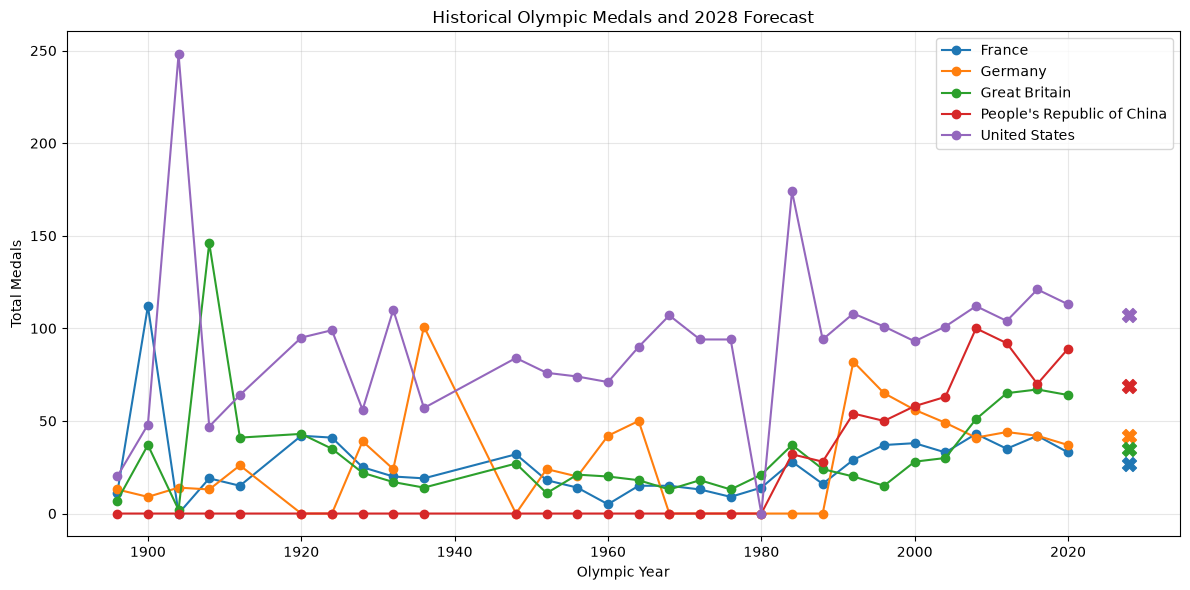

In [14]:

# Final step: Forecast next Olympic edition and plot historical trends

# Train on all available historical data
X = forecast_pivot.index.to_numpy().reshape(-1, 1)
future_year = np.array([[2028]])

# Store forecasts for all five countries
forecasts = {}

for country in forecast_pivot.columns:
    # Train the model using the country's complete history
    model = LinearRegression()
    model.fit(X, forecast_pivot[country].to_numpy())

    # Predict medals for the next scheduled Summer Olympics
    prediction = model.predict(future_year)[0]
    forecasts[country] = max(0, round(prediction))

# Display the forecast table
forecast_results = pd.DataFrame({
    "Country": list(forecasts.keys()),
    "Forecast_Medals": list(forecasts.values())
})
display(forecast_results)

# Plot historical medal counts and the forecast
plt.figure(figsize=(12, 6))

for country in forecast_pivot.columns:
    plt.plot(
        forecast_pivot.index,
        forecast_pivot[country],
        marker="o",
        label=country
    )
    plt.scatter(
        2028,
        forecasts[country],
        marker="X",
        s=100
    )

plt.title("Historical Olympic Medals and 2028 Forecast")
plt.xlabel("Olympic Year")
plt.ylabel("Total Medals")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


#### Linear Regression was used to forecast medal counts based on historical trends.

#### Forecasts are estimates, not guaranteed outcomes; Olympic performance changes across editions.

#### China was included instead of the Soviet Union because the Soviet Union no longer competes as a country.

### Key Insights: Trends, Seasonality and Forecasts

1. **Trend:** The United States has the highest historical medal count among the selected countries. China's medal performance has also grown significantly over the historical period.

2. **Seasonality:** Olympic Games generally occur every four years. However, medal counts do not follow a fixed seasonal pattern because athlete performance and competition vary across editions.

3. **Forecast:** Linear Regression estimates future medal counts using historical trends. These predictions are approximate and may not capture sudden changes in country performance.

4. **Limitation:** The dataset ends in 2020, so the forecast does not account for the 2024 Olympic results. China was included instead of the discontinued Soviet Union for a more relevant comparison.